<a href="https://colab.research.google.com/github/ajithosh229/MACHINE-LEARNING/blob/main/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load Data
# (Assuming the target column is named 'Outcome' as in the standard Pima Diabetes dataset)
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/diabetes.csv')

# 2. Separate Features (X) and Target (y)
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 3. Split Data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Feature Scaling (Crucial for KNN and SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data successfully split and scaled.")
print(f"Training features shape: {X_train_scaled.shape}")
print(f"Testing features shape: {X_test_scaled.shape}")

Mounted at /content/drive
Data successfully split and scaled.
Training features shape: (614, 8)
Testing features shape: (154, 8)


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Load the dataset
df = pd.read_csv('diabetes.csv')

print("--- 1. INITIAL DATA OVERVIEW ---")
print(f"Total dataset shape: {df.shape} (rows, columns)\n")
print("First 5 rows of the original dataset:")
display(df.head())

print("\n--- 2. MISSING VALUES CHECK ---")
# Check if there are any empty/null values in the dataset
missing_values = df.isnull().sum()
print(missing_values)

# 2. Separate Features (X) and Target (y)
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 3. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n--- 3. DATA SPLITTING ---")
print(f"X_train shape (Training Features): {X_train.shape} -> Used to teach the model.")
print(f"y_train shape (Training Target):   {y_train.shape} -> The actual answers for training.")
print(f"X_test shape  (Testing Features):  {X_test.shape} -> Used to test the model.")
print(f"y_test shape  (Testing Target):    {y_test.shape} -> The actual answers for testing.")

# 4. Data Preprocessing (Feature Scaling)
# Algorithms like KNN and SVM require data to be on the same scale
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)
# Only transform testing data (do NOT fit) to prevent data leakage
X_test_scaled = scaler.transform(X_test)

# Convert the scaled array back to a DataFrame just so it prints beautifully
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

print("\n--- 4. DATA PREPROCESSING (SCALING) OUTPUT ---")
print("First 5 rows of the SCALED Training Features:")
print("(Notice how the values are now standardized, mostly between -3 and 3)")
display(X_train_scaled_df.head())

--- 1. INITIAL DATA OVERVIEW ---
Total dataset shape: (768, 9) (rows, columns)

First 5 rows of the original dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



--- 2. MISSING VALUES CHECK ---
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

--- 3. DATA SPLITTING ---
X_train shape (Training Features): (614, 8) -> Used to teach the model.
y_train shape (Training Target):   (614,) -> The actual answers for training.
X_test shape  (Testing Features):  (154, 8) -> Used to test the model.
y_test shape  (Testing Target):    (154,) -> The actual answers for testing.

--- 4. DATA PREPROCESSING (SCALING) OUTPUT ---
First 5 rows of the SCALED Training Features:
(Notice how the values are now standardized, mostly between -3 and 3)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.526397,-1.151398,-3.752683,-1.322774,-0.701206,-4.135256,-0.490735,-1.035940
1,1.588046,-0.276643,0.680345,0.233505,-0.701206,-0.489169,2.415030,1.487101
2,-0.828460,0.566871,-1.265862,-0.090720,0.013448,-0.424522,0.549161,-0.948939
3,-1.130523,1.254179,-1.049617,-1.322774,-0.701206,-1.303720,-0.639291,2.792122
4,0.681856,0.410665,0.572222,1.076490,2.484601,1.838121,-0.686829,1.139095


--- K-NEAREST NEIGHBORS (KNN) ---
KNN Accuracy: 69.48%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.77        99
           1       0.58      0.51      0.54        55

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.66       154
weighted avg       0.69      0.69      0.69       154



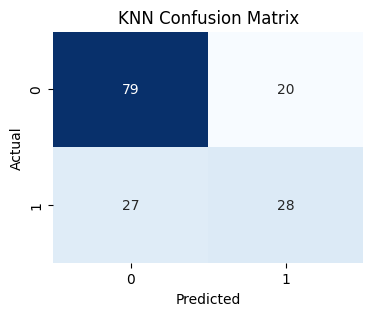

In [4]:
from sklearn.neighbors import KNeighborsClassifier

print("--- K-NEAREST NEIGHBORS (KNN) ---")

# Initialize and Train
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Predict
knn_pred = knn_model.predict(X_test_scaled)

# Evaluate and Print
knn_acc = accuracy_score(y_test, knn_pred)
print(f"KNN Accuracy: {knn_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

# Confusion Matrix
plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

--- SUPPORT VECTOR MACHINE (SVM) ---
SVM Accuracy: 73.38%

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80        99
           1       0.65      0.56      0.60        55

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



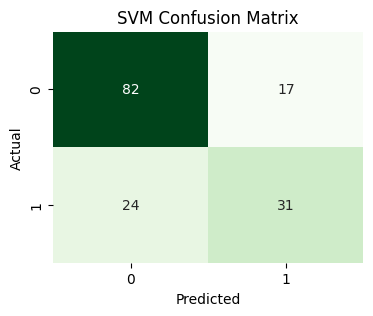

In [5]:
from sklearn.svm import SVC

print("--- SUPPORT VECTOR MACHINE (SVM) ---")

# Initialize and Train
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Predict
svm_pred = svm_model.predict(X_test_scaled)

# Evaluate and Print
svm_acc = accuracy_score(y_test, svm_pred)
print(f"SVM Accuracy: {svm_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, svm_pred))

# Confusion Matrix
plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

--- DECISION TREE ---
Decision Tree Accuracy: 74.68%

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.79        99
           1       0.62      0.73      0.67        55

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154



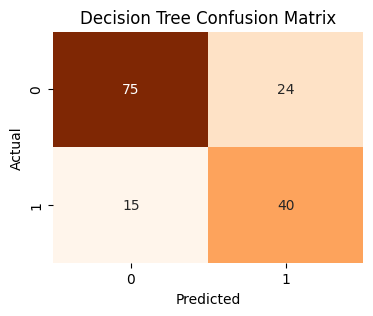

In [6]:
from sklearn.tree import DecisionTreeClassifier

print("--- DECISION TREE ---")

# Initialize and Train
# Note: Decision Trees do not strictly require scaled data, but using the scaled data
# here keeps the evaluation fair and consistent across all three models.
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

# Predict
dt_pred = dt_model.predict(X_test_scaled)

# Evaluate and Print
dt_acc = accuracy_score(y_test, dt_pred)
print(f"Decision Tree Accuracy: {dt_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

# Confusion Matrix
plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

--- ALGORITHM COMPARISON ---
1. Decision Tree: 74.68%
2. SVM: 73.38%
3. KNN: 69.48%


/tmp/ipykernel_8672/755489169.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()), palette='coolwarm')


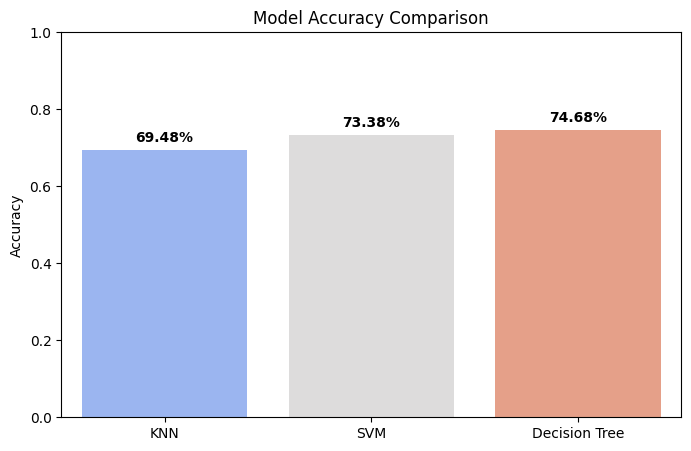

In [7]:
print("--- ALGORITHM COMPARISON ---")

# Store accuracies in a dictionary for easy plotting
accuracies = {
    "KNN": knn_acc,
    "SVM": svm_acc,
    "Decision Tree": dt_acc
}

# Print sorted results
sorted_acc = dict(sorted(accuracies.items(), key=lambda item: item[1], reverse=True))
for rank, (name, acc) in enumerate(sorted_acc.items(), 1):
    print(f"{rank}. {name}: {acc * 100:.2f}%")

# Plot the comparison
plt.figure(figsize=(8, 5))
sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()), palette='coolwarm')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

# Add percentage text on top of bars
for i, acc in enumerate(accuracies.values()):
    plt.text(i, acc + 0.02, f"{acc*100:.2f}%", ha='center', fontweight='bold')

plt.show()